In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.metrics import classification_report, roc_auc_score, mean_squared_error, r2_score

# Set up clean plotting visuals inside the notebook
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.figsize': (12, 6), 'font.size': 11})

# Load the file using your exact Windows C path and file name
file_path = r"C:\Users\User\Documents\PYTHON AND STOCKS\archive (4)\viral_songs.csv"
df = pd.read_csv(file_path)

print(f"Data successfully loaded! Total rows: {len(df)}")


Data successfully loaded! Total rows: 10000


In [2]:
# Grouping columns by audio characteristics
audio_features = [
    'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm', 
    'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness_db'
]

print("Audio features targeted for analysis defined.")


Audio features targeted for analysis defined.


--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       0.79      0.70      0.74      1279
           1       0.55      0.66      0.60       721

    accuracy                           0.68      2000
   macro avg       0.67      0.68      0.67      2000
weighted avg       0.70      0.68      0.69      2000

ROC-AUC Score: 0.7656



C:\Users\User\AppData\Local\Temp\ipykernel_9112\652135452.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis')


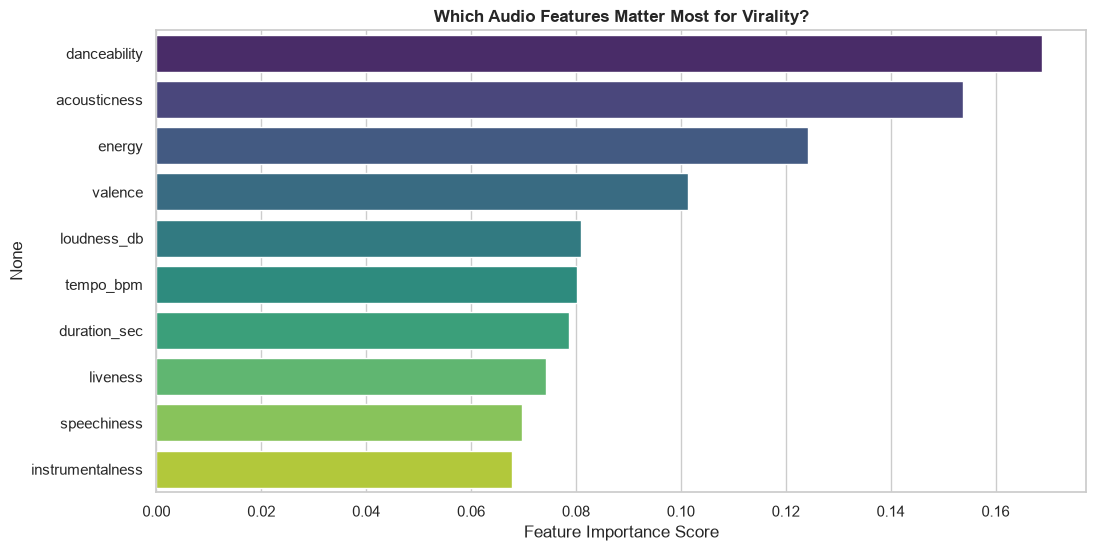

In [3]:
# Set up classification targets
X_clf = df[audio_features]
y_clf = df['viral']

# Split data keeping the viral balance stable
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# Train the Classifier
clf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
clf_model.fit(X_train_c, y_train_c)

# Evaluate results
y_pred_c = clf_model.predict(X_test_c)
y_prob_c = clf_model.predict_proba(X_test_c)[:, 1]

print("--- CLASSIFICATION REPORT ---")
print(classification_report(y_test_c, y_pred_c))
print(f"ROC-AUC Score: {roc_auc_score(y_test_c, y_prob_c):.4f}\n")

# Plot feature importance chart directly under the cell
feat_imp = pd.Series(clf_model.feature_importances_, index=audio_features).sort_values(ascending=False)
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis')
plt.title('Which Audio Features Matter Most for Virality?', fontweight='bold')
plt.xlabel('Feature Importance Score')
plt.show()


In [4]:
# Apply log transform to eliminate skewness in stream counts
df['log_streams'] = np.log1p(df['streams'])

X_reg = df[audio_features]
y_reg = df['log_streams']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Scale features for linear modeling scaling standards
scaler = StandardScaler()
X_train_r_scaled = scaler.fit_transform(X_train_r)
X_test_r_scaled = scaler.transform(X_test_r)

# Run Regression
reg_model = Ridge(alpha=1.0)
reg_model.fit(X_train_r_scaled, y_train_r)
y_pred_r = reg_model.predict(X_test_r_scaled)

print("--- REGRESSION PERFORMANCE ---")
print(f"Log-Streams Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test_r, y_pred_r)):.4f}")
print(f"Log-Streams R² Score (Variance Explained): {r2_score(y_test_r, y_pred_r):.4f}")


--- REGRESSION PERFORMANCE ---
Log-Streams Root Mean Squared Error (RMSE): 1.9397
Log-Streams R² Score (Variance Explained): 0.0752


--- GENRE OVER-INDEXING METRICS ---
        genre  Total_Tracks  Viral_Tracks  Viral_Rate  Viral_Rate_%
0       Latin          1030           666    0.646602     64.660194
1         Pop          1002           619    0.617764     61.776447
2     Hip-Hop          1052           643    0.611217     61.121673
3  Electronic           991           502    0.506559     50.655903
4         R&B           950           385    0.405263     40.526316
5        Rock          1084           354    0.326568     32.656827
6     Country           942           225    0.238854     23.885350
7       Indie           993           138    0.138973     13.897281
8        Jazz           965            61    0.063212      6.321244
9   Classical           991            12    0.012109      1.210898


C:\Users\User\AppData\Local\Temp\ipykernel_9112\2757500813.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=genre_analysis, x='genre', y='Viral_Rate_%', palette='coolwarm')


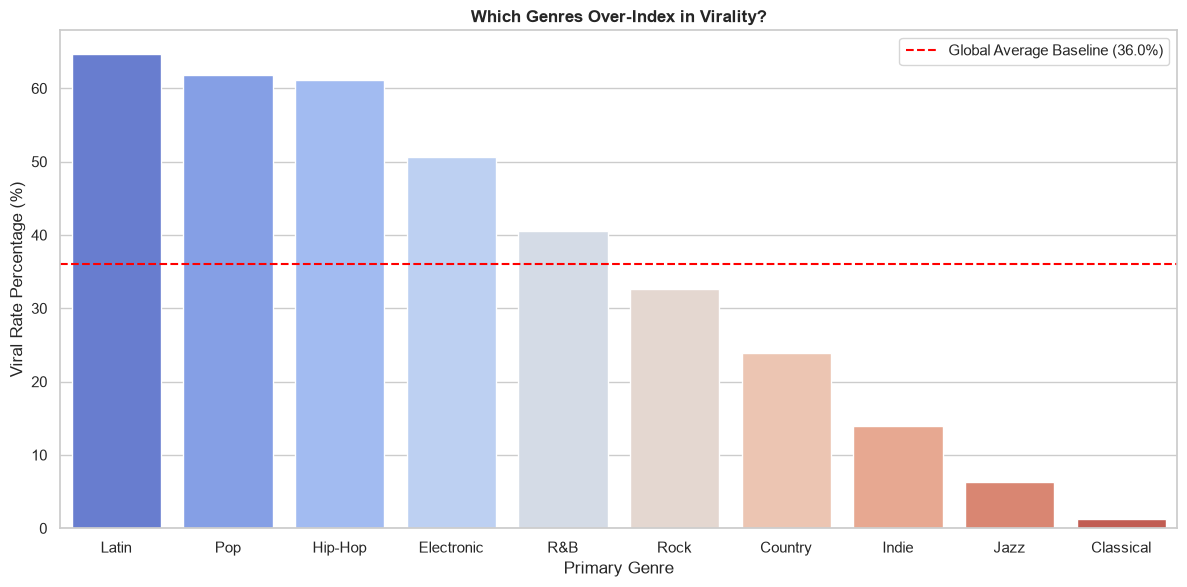

In [5]:
# Calculate viral rates per musical genre
genre_analysis = df.groupby('genre').agg(
    Total_Tracks=('viral', 'count'),
    Viral_Tracks=('viral', 'sum'),
    Viral_Rate=('viral', 'mean')
).sort_values(by='Viral_Rate', ascending=False).reset_index()

genre_analysis['Viral_Rate_%'] = genre_analysis['Viral_Rate'] * 100
print("--- GENRE OVER-INDEXING METRICS ---")
print(genre_analysis)

# Plot the distribution comparison with the average global baseline
sns.barplot(data=genre_analysis, x='genre', y='Viral_Rate_%', palette='coolwarm')
global_baseline = df['viral'].mean() * 100
plt.axhline(global_baseline, color='red', linestyle='--', label=f'Global Average Baseline ({global_baseline:.1f}%)')

plt.title('Which Genres Over-Index in Virality?', fontweight='bold')
plt.ylabel('Viral Rate Percentage (%)')
plt.xlabel('Primary Genre')
plt.legend()
plt.tight_layout()
plt.show()
